# Smart Crop Yield Prediction — Classification Notebook Revised for AIP Report

Notebook ini disesuaikan dengan laporan baru bergaya AIP Conference Proceedings. Target asli dataset adalah `Yield_ton_per_ha` yang berbentuk numerik kontinu. Karena kebutuhan notebook ini menggunakan algoritma klasifikasi, target dikonversi menjadi tiga kelas produktivitas: **Low**, **Medium**, dan **High**.

Sumber dataset: https://www.kaggle.com/datasets/miadul/smart-crop-yield-predication-dataset

Catatan metodologis: apabila tujuan penelitian adalah memprediksi angka ton/ha secara langsung, pendekatan yang paling tepat adalah regresi. Notebook ini khusus diposisikan sebagai klasifikasi tingkat produktivitas untuk kebutuhan pengambilan keputusan berbasis kategori.

## 1. Import Library

In [1]:
try:
    import imblearn
except ImportError:
    !pip install -q imbalanced-learn

import os
import warnings
import joblib
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, label_binarize
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2, f_classif
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

## 2. Konfigurasi Notebook

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
K_BEST = 10

TARGET_NUMERIC = "Yield_ton_per_ha"
TARGET_CLASS = "Yield_Class"
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_TO_INT = {label: idx for idx, label in enumerate(CLASS_ORDER)}
INT_TO_CLASS = {idx: label for label, idx in CLASS_TO_INT.items()}

MODEL_OUTPUT_PATH = "crop_yield_classification_model_revised.pkl"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.random.seed(RANDOM_STATE)

## 3. Business Objective

Sektor pertanian menghadapi ketidakpastian tinggi karena hasil panen dipengaruhi oleh interaksi antara kondisi tanah, cuaca, input budidaya, dan keputusan manajemen lahan. Machine learning banyak digunakan dalam pertanian presisi untuk membantu estimasi hasil panen dan pengambilan keputusan berbasis data [1]. Systematic literature review tentang crop yield prediction juga menunjukkan bahwa variabel cuaca, tanah, dan input budidaya merupakan kelompok fitur yang sering digunakan dalam pemodelan hasil panen [2].

Tujuan bisnis notebook ini adalah membangun model klasifikasi tingkat hasil panen tanaman ke dalam kelas **Low**, **Medium**, dan **High**. Pendekatan klasifikasi dipilih agar output model lebih mudah diterjemahkan menjadi keputusan operasional, misalnya prioritas evaluasi input pada kelas Low atau identifikasi pola budidaya produktif pada kelas High.

**Gap proyek.** Sebagian besar studi crop yield prediction dan laporan sebelumnya lebih berfokus pada prediksi nilai yield secara regresi. Gap yang dijawab notebook ini adalah menguji pendekatan klasifikasi kelas produktivitas dengan pipeline lengkap: konversi target numerik menjadi kelas, balancing dataset menggunakan SMOTE, seleksi fitur eksplisit menggunakan beberapa algoritma, serta perbandingan model Gaussian Naive Bayes dan Decision Tree Classifier.

## 4. Original Data

In [3]:
# Cara penggunaan di Google Colab:
# 1. Upload file crop_yield_dataset.csv ke session Colab, atau
# 2. Simpan file di Google Drive dan sesuaikan DATA_PATH.

DATA_PATH = "crop_yield_dataset.csv"

if not os.path.exists(DATA_PATH):
    possible_paths = [
        "/content/crop_yield_dataset.csv",
        "/mnt/data/crop_yield_dataset.csv"
    ]
    for path in possible_paths:
        if os.path.exists(path):
            DATA_PATH = path
            break

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError("File crop_yield_dataset.csv belum ditemukan. Upload file ke Colab terlebih dahulu.")

df_original = pd.read_csv(DATA_PATH)
df_original.head()

,Crop,Region,Soil_Type,Soil_pH,Rainfall_mm,Temperature_C,Humidity_pct,Fertilizer_Used_kg,Irrigation,Pesticides_Used_kg,Planting_Density,Previous_Crop,Yield_ton_per_ha
0,Maize,Region_C,Sandy,7.0100,"1,485.4000",19.7000,40.3000,105.1000,Drip,10.2000,23.2000,Rice,101.4800
1,Barley,Region_D,Loam,5.7900,399.4000,29.1000,55.4000,221.8000,Sprinkler,35.5000,7.4000,Barley,127.3900
2,Rice,Region_C,Clay,7.2400,980.9000,30.5000,74.4000,61.2000,Sprinkler,40.0000,5.1000,Wheat,68.9900
3,Maize,Region_D,Loam,6.7900,"1,054.3000",26.4000,62.0000,257.8000,Drip,42.7000,23.7000,NaN,169.0600
4,Maize,Region_D,Sandy,5.9600,744.6000,20.4000,70.9000,195.8000,Drip,25.5000,15.6000,Maize,118.7100


## 5. Data Understanding

In [4]:
print("Shape dataset:", df_original.shape)
print("\nInformasi struktur data:")
df_original.info()

print("\nJumlah missing value per kolom:")
display(df_original.isna().sum().to_frame("missing_count"))

print("\nJumlah nilai unik per kolom:")
display(df_original.nunique().to_frame("unique_count"))

print("\nStatistik deskriptif fitur numerik:")
display(df_original.describe())

Shape dataset: (10000, 13)

Informasi struktur data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Crop                10000 non-null  object 
 1   Region              10000 non-null  object 
 2   Soil_Type           10000 non-null  object 
 3   Soil_pH             10000 non-null  float64
 4   Rainfall_mm         10000 non-null  float64
 5   Temperature_C       10000 non-null  float64
 6   Humidity_pct        10000 non-null  float64
 7   Fertilizer_Used_kg  10000 non-null  float64
 8   Irrigation          7462 non-null   object 
 9   Pesticides_Used_kg  10000 non-null  float64
 10  Planting_Density    10000 non-null  float64
 11  Previous_Crop       7969 non-null   object 
 12  Yield_ton_per_ha    10000 non-null  float64
dtypes: float64(8), object(5)
memory usage: 1015.8+ KB

Jumlah missing value per kolom:


,missing_count
Crop,0
Region,0
Soil_Type,0
Soil_pH,0
Rainfall_mm,0
Temperature_C,0
Humidity_pct,0
Fertilizer_Used_kg,0
Irrigation,2538
Pesticides_Used_kg,0



Jumlah nilai unik per kolom:


,unique_count
Crop,4
Region,4
Soil_Type,3
Soil_pH,201
Rainfall_mm,6964
Temperature_C,201
Humidity_pct,601
Fertilizer_Used_kg,2450
Irrigation,3
Pesticides_Used_kg,501



Statistik deskriptif fitur numerik:


,Soil_pH,Rainfall_mm,Temperature_C,Humidity_pct,Fertilizer_Used_kg,Pesticides_Used_kg,Planting_Density,Yield_ton_per_ha
count,"10,000.0000","10,000.0000","10,000.0000","10,000.0000","10,000.0000","10,000.0000","10,000.0000","10,000.0000"
mean,6.5167,843.6647,24.9758,60.0525,175.0833,25.0555,14.9979,117.8911
std,0.5748,373.6708,5.7906,17.3171,71.9642,14.3535,5.8331,37.9727
min,5.5000,200.0000,15.0000,30.0000,50.0000,0.0000,5.0000,28.4500
25%,6.0200,518.0000,20.0000,45.1000,113.3000,12.6000,9.9000,87.1350
50%,6.5200,845.3000,24.9000,60.2000,175.0000,25.3000,15.0000,117.7050
75%,7.0100,"1,161.8500",30.1000,75.1000,237.9000,37.5000,20.1000,149.1475
max,7.5000,"1,499.7000",35.0000,90.0000,300.0000,50.0000,25.0000,207.2100


## 6. Exploratory Data Analysis (EDA)

In [5]:
numeric_cols = df_original.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_original.select_dtypes(include=["object", "category"]).columns.tolist()

print("Kolom numerik:", numeric_cols)
print("Kolom kategorikal:", categorical_cols)

Kolom numerik: ['Soil_pH', 'Rainfall_mm', 'Temperature_C', 'Humidity_pct', 'Fertilizer_Used_kg', 'Pesticides_Used_kg', 'Planting_Density', 'Yield_ton_per_ha']
Kolom kategorikal: ['Crop', 'Region', 'Soil_Type', 'Irrigation', 'Previous_Crop']


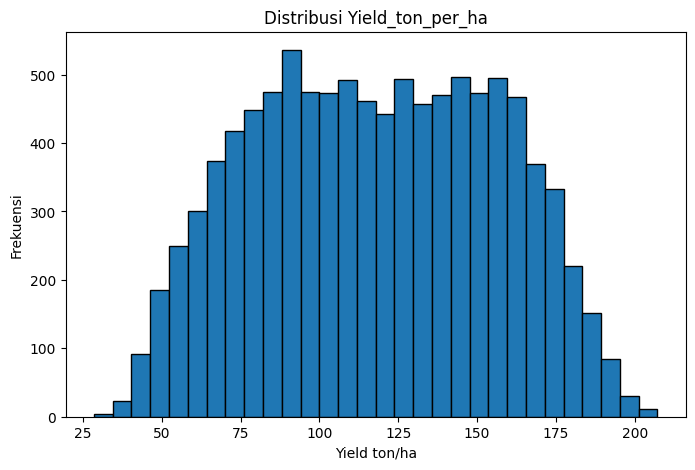

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(df_original[TARGET_NUMERIC], bins=30, edgecolor="black")
plt.title("Distribusi Yield_ton_per_ha")
plt.xlabel("Yield ton/ha")
plt.ylabel("Frekuensi")
plt.show()

<Figure size 1000x500 with 0 Axes>

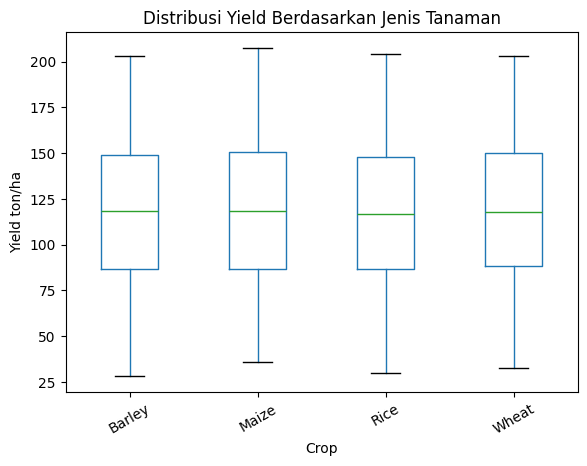

In [7]:
plt.figure(figsize=(10, 5))
df_original.boxplot(column=TARGET_NUMERIC, by="Crop", grid=False)
plt.title("Distribusi Yield Berdasarkan Jenis Tanaman")
plt.suptitle("")
plt.xlabel("Crop")
plt.ylabel("Yield ton/ha")
plt.xticks(rotation=30)
plt.show()

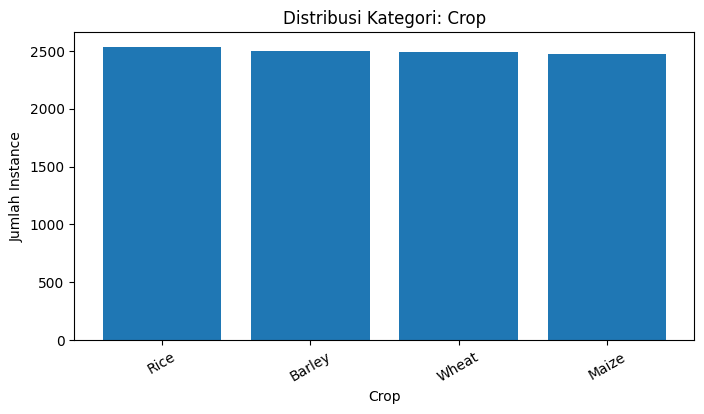

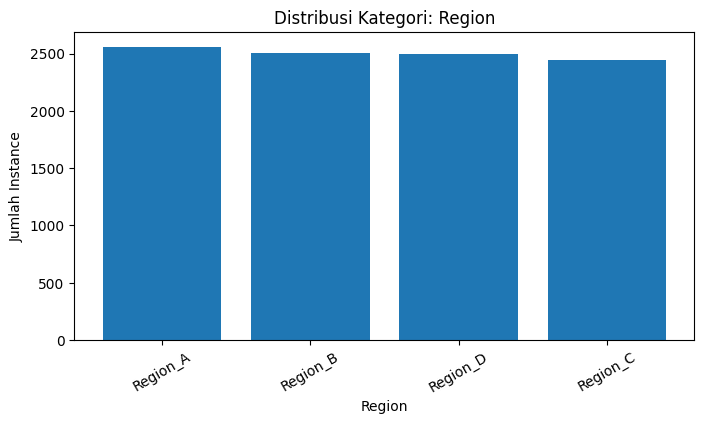

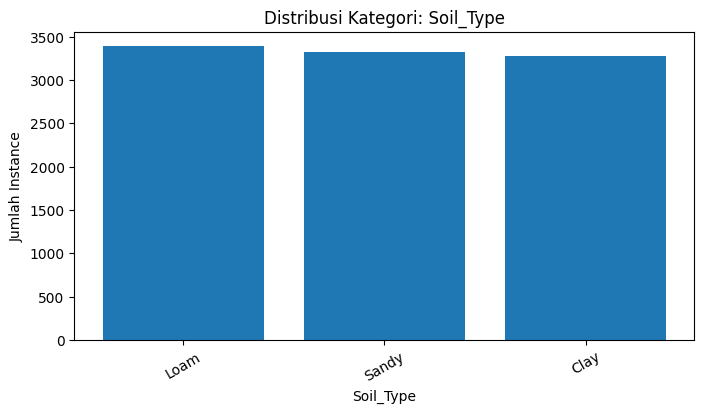

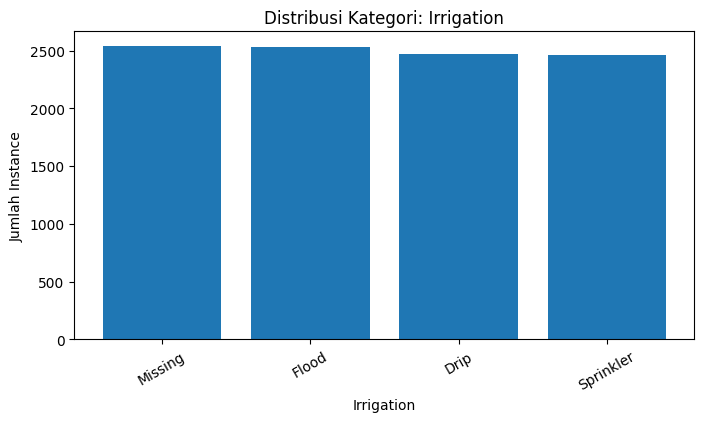

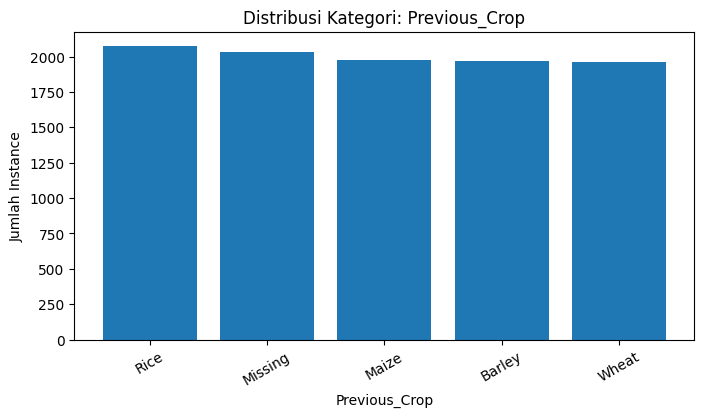

In [8]:
for col in categorical_cols:
    counts = df_original[col].fillna("Missing").value_counts()
    plt.figure(figsize=(8, 4))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title(f"Distribusi Kategori: {col}")
    plt.xlabel(col)
    plt.ylabel("Jumlah Instance")
    plt.xticks(rotation=30)
    plt.show()

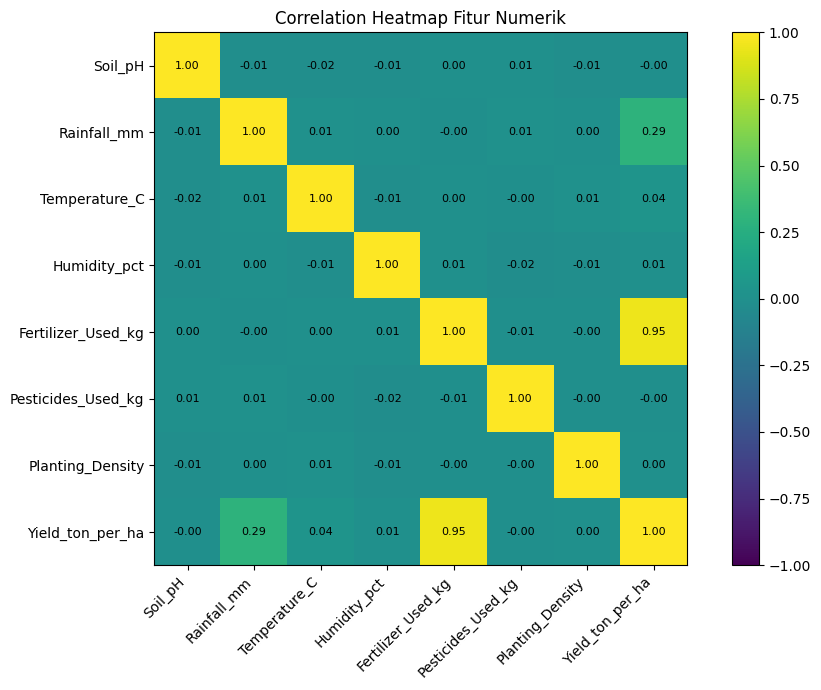

In [9]:
corr_matrix = df_original[numeric_cols].corr()
plt.figure(figsize=(10, 7))
im = plt.imshow(corr_matrix, vmin=-1, vmax=1)
plt.colorbar(im)
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.index)), corr_matrix.index)
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation Heatmap Fitur Numerik")
plt.tight_layout()
plt.show()

## 7. Target Data

Target asli `Yield_ton_per_ha` dikonversi menjadi tiga kelas menggunakan kuantil agar distribusi kelas relatif seimbang.

- **Low**: hasil panen rendah
- **Medium**: hasil panen sedang
- **High**: hasil panen tinggi

Konversi ini mengubah formulation dari regresi ke klasifikasi. Kelas yang terbentuk bersifat relatif terhadap distribusi dataset, bukan standar agronomis universal.

In [10]:
df = df_original.copy()

df[TARGET_CLASS], yield_bins = pd.qcut(
    df[TARGET_NUMERIC],
    q=3,
    labels=CLASS_ORDER,
    retbins=True,
    duplicates="drop"
)

df[TARGET_CLASS] = df[TARGET_CLASS].astype(str).map(CLASS_TO_INT)

print("Batas kuantil target:")
for i in range(len(yield_bins) - 1):
    print(f"{CLASS_ORDER[i]}: {yield_bins[i]:.2f} sampai {yield_bins[i+1]:.2f}")

class_distribution = df[TARGET_CLASS].value_counts().sort_index().rename(index=INT_TO_CLASS)
display(class_distribution.to_frame("jumlah_instance"))

Batas kuantil target:
Low: 28.45 sampai 96.72
Medium: 96.72 sampai 139.07
High: 139.07 sampai 207.21


,jumlah_instance
Yield_Class,
Low,3333
Medium,3333
High,3334


## 8. Data Cleaning

In [11]:
df_clean = df.copy()

feature_columns_raw = df_clean.drop(columns=[TARGET_NUMERIC, TARGET_CLASS]).columns.tolist()
numeric_features = df_clean[feature_columns_raw].select_dtypes(include=np.number).columns.tolist()
categorical_features = df_clean[feature_columns_raw].select_dtypes(include=["object", "category"]).columns.tolist()

missing_before = df_clean.isna().sum()

for col in numeric_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_features:
    df_clean[col] = df_clean[col].fillna("Unknown")

missing_after = df_clean.isna().sum()

missing_comparison = pd.DataFrame({
    "sebelum": missing_before,
    "sesudah": missing_after
})
display(missing_comparison[missing_comparison["sebelum"] > 0])

,sebelum,sesudah
Irrigation,2538,0
Previous_Crop,2031,0


## 9. Label Encoding

In [12]:
df_encoded = df_clean.copy()
label_encoders = {}

for col in categorical_features:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = encoder

print("Mapping target:", CLASS_TO_INT)
print("Contoh data setelah label encoding:")
display(df_encoded.head())

Mapping target: {'Low': 0, 'Medium': 1, 'High': 2}
Contoh data setelah label encoding:


,Crop,Region,Soil_Type,Soil_pH,Rainfall_mm,Temperature_C,Humidity_pct,Fertilizer_Used_kg,Irrigation,Pesticides_Used_kg,Planting_Density,Previous_Crop,Yield_ton_per_ha,Yield_Class
0,1,2,2,7.0100,"1,485.4000",19.7000,40.3000,105.1000,0,10.2000,23.2000,2,101.4800,1
1,0,3,1,5.7900,399.4000,29.1000,55.4000,221.8000,2,35.5000,7.4000,0,127.3900,1
2,2,2,0,7.2400,980.9000,30.5000,74.4000,61.2000,2,40.0000,5.1000,4,68.9900,0
3,1,3,1,6.7900,"1,054.3000",26.4000,62.0000,257.8000,0,42.7000,23.7000,3,169.0600,2
4,1,3,2,5.9600,744.6000,20.4000,70.9000,195.8000,0,25.5000,15.6000,1,118.7100,1


## 10. Feature Engineering

In [13]:
df_featured = df_encoded.copy()

df_featured["Rainfall_per_Temperature"] = df_featured["Rainfall_mm"] / (df_featured["Temperature_C"] + 1)
df_featured["Fertilizer_per_Density"] = df_featured["Fertilizer_Used_kg"] / (df_featured["Planting_Density"] + 1)
df_featured["Humidity_Temperature_Index"] = df_featured["Humidity_pct"] * df_featured["Temperature_C"]
df_featured["Input_Intensity"] = df_featured["Fertilizer_Used_kg"] + df_featured["Pesticides_Used_kg"]

engineered_features = [
    "Rainfall_per_Temperature",
    "Fertilizer_per_Density",
    "Humidity_Temperature_Index",
    "Input_Intensity"
]

display(df_featured[engineered_features].head())

,Rainfall_per_Temperature,Fertilizer_per_Density,Humidity_Temperature_Index,Input_Intensity
0,71.7585,4.3430,793.9100,115.3000
1,13.2691,26.4048,"1,612.1400",257.3000
2,31.1397,10.0328,"2,269.2000",101.2000
3,38.4781,10.4372,"1,636.8000",300.5000
4,34.7944,11.7952,"1,446.3600",221.3000


## 11. Distribusi Instance

,jumlah_instance
Yield_Class,
Low,3333
Medium,3333
High,3334


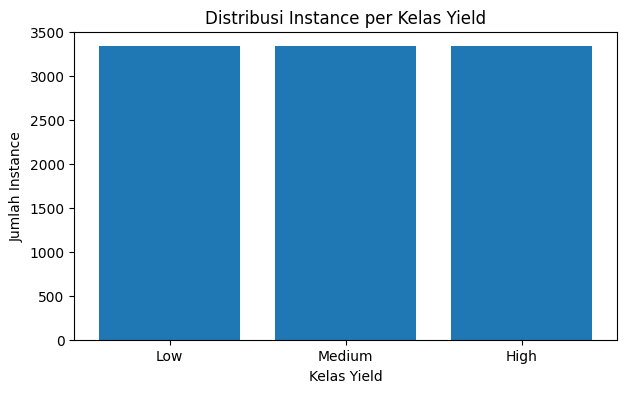

In [14]:
class_distribution = df_featured[TARGET_CLASS].value_counts().sort_index().rename(index=INT_TO_CLASS)
display(class_distribution.to_frame("jumlah_instance"))

plt.figure(figsize=(7, 4))
plt.bar(class_distribution.index, class_distribution.values)
plt.title("Distribusi Instance per Kelas Yield")
plt.xlabel("Kelas Yield")
plt.ylabel("Jumlah Instance")
plt.show()

## 12. Train-Test Split

In [15]:
X = df_featured.drop(columns=[TARGET_NUMERIC, TARGET_CLASS])
y = df_featured[TARGET_CLASS]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

display(pd.Series(y_train).value_counts().sort_index().rename(index=INT_TO_CLASS).to_frame("train_count"))
display(pd.Series(y_test).value_counts().sort_index().rename(index=INT_TO_CLASS).to_frame("test_count"))

X_train: (8000, 16)
X_test : (2000, 16)
y_train: (8000,)
y_test : (2000,)


,train_count
Yield_Class,
Low,2666
Medium,2667
High,2667


,test_count
Yield_Class,
Low,667
Medium,666
High,667


## 13. Balancing Dataset

Balancing dilakukan menggunakan **SMOTE** hanya pada data latih agar data uji tetap merepresentasikan data asli. Rumus dasar SMOTE:

$$x_{new}=x_i+\lambda(x_{nn}-x_i), \quad 0 \leq \lambda \leq 1$$

Data sintetis dibuat di antara satu instance dan tetangga terdekatnya pada kelas yang membutuhkan penyeimbangan.

In [16]:
print("Distribusi sebelum balancing:")
display(pd.Series(y_train).value_counts().sort_index().rename(index=INT_TO_CLASS).to_frame("count"))

smote = SMOTE(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("\nDistribusi setelah balancing:")
display(pd.Series(y_train_balanced).value_counts().sort_index().rename(index=INT_TO_CLASS).to_frame("count"))

Distribusi sebelum balancing:


,count
Yield_Class,
Low,2666
Medium,2667
High,2667



Distribusi setelah balancing:


,count
Yield_Class,
Low,2667
Medium,2667
High,2667


## 14. Feature Selection

Seleksi fitur menggunakan empat pendekatan:

1. **Mutual Information** sebagai selector utama karena dapat menangkap hubungan nonlinier antara fitur dan target.
2. **Chi-Square** sebagai pembanding asosiasi fitur non-negatif dengan kelas.
3. **ANOVA F-test** sebagai pembanding perbedaan rata-rata fitur antar kelas.
4. **Decision Tree Importance** sebagai metode embedded berbasis penurunan impurity.

Rumus penting:

$$I(X;Y)=\sum_x\sum_y p(x,y)\log\frac{p(x,y)}{p(x)p(y)}$$

$$\chi^2=\sum_i\frac{(O_i-E_i)^2}{E_i}$$

$$F=\frac{MS_{between}}{MS_{within}}$$

$$FI_j=\sum_{t:v(t)=j}\frac{N_t}{N}\left(I_t-\frac{N_L}{N_t}I_L-\frac{N_R}{N_t}I_R\right)$$

In [17]:
K_BEST = min(K_BEST, X_train_balanced.shape[1])

# 1. Mutual Information - final selector
mi_score_func = partial(mutual_info_classif, random_state=RANDOM_STATE)
mi_selector = SelectKBest(
    score_func=mi_score_func,
    k=K_BEST
)
X_train_selected = mi_selector.fit_transform(X_train_balanced, y_train_balanced)
X_test_selected = mi_selector.transform(X_test)
selected_features = X_train_balanced.columns[mi_selector.get_support()].tolist()

# 2. Chi-Square - requires non-negative values
minmax = MinMaxScaler()
X_train_nonnegative = pd.DataFrame(
    minmax.fit_transform(X_train_balanced),
    columns=X_train_balanced.columns
)
chi_selector = SelectKBest(score_func=chi2, k=K_BEST)
chi_selector.fit(X_train_nonnegative, y_train_balanced)

# 3. ANOVA F-test
anova_selector = SelectKBest(score_func=f_classif, k=K_BEST)
anova_selector.fit(X_train_balanced, y_train_balanced)

# 4. Embedded Decision Tree Importance
tree_for_selection = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
tree_for_selection.fit(X_train_balanced, y_train_balanced)

feature_selection_scores = pd.DataFrame({
    "feature": X_train_balanced.columns,
    "mutual_information": mi_selector.scores_,
    "chi_square": chi_selector.scores_,
    "anova_f": anova_selector.scores_,
    "tree_importance": tree_for_selection.feature_importances_,
    "selected_by_mi": mi_selector.get_support()
}).sort_values("mutual_information", ascending=False)

display(feature_selection_scores)
print("Fitur final yang dipilih Mutual Information:")
print(selected_features)

,feature,mutual_information,chi_square,anova_f,tree_importance,selected_by_mi
7,Fertilizer_Used_kg,0.7378,"1,071.9813","17,011.1229",0.8515,True
15,Input_Intensity,0.6854,752.6477,"13,977.9306",0.0004,True
13,Fertilizer_per_Density,0.3372,356.2016,"2,100.7812",0.0000,True
4,Rainfall_mm,0.0347,72.0717,226.9034,0.1476,True
12,Rainfall_per_Temperature,0.0306,35.2636,146.6821,0.0000,True
6,Humidity_pct,0.0131,0.7402,2.2287,0.0002,True
1,Region,0.0117,1.4190,2.5009,0.0000,True
2,Soil_Type,0.0070,0.6290,0.9622,0.0000,True
3,Soil_pH,0.0058,0.0469,0.1432,0.0000,True
9,Pesticides_Used_kg,0.0043,1.8418,5.6596,0.0000,True


Fitur final yang dipilih Mutual Information:
['Region', 'Soil_Type', 'Soil_pH', 'Rainfall_mm', 'Humidity_pct', 'Fertilizer_Used_kg', 'Pesticides_Used_kg', 'Rainfall_per_Temperature', 'Fertilizer_per_Density', 'Input_Intensity']


## 15. Dataset Final

In [18]:
X_train_final = pd.DataFrame(X_train_selected, columns=selected_features)
X_test_final = pd.DataFrame(X_test_selected, columns=selected_features)

print("Dataset final untuk training dan testing:")
print("X_train_final:", X_train_final.shape)
print("X_test_final :", X_test_final.shape)
print("y_train_balanced:", y_train_balanced.shape)
print("y_test:", y_test.shape)

display(X_train_final.head())

Dataset final untuk training dan testing:
X_train_final: (8001, 10)
X_test_final : (2000, 10)
y_train_balanced: (8001,)
y_test: (2000,)


,Region,Soil_Type,Soil_pH,Rainfall_mm,Humidity_pct,Fertilizer_Used_kg,Pesticides_Used_kg,Rainfall_per_Temperature,Fertilizer_per_Density,Input_Intensity
0,1.0000,1.0000,6.1900,"1,308.5000",87.1000,215.3000,6.8000,51.1133,13.4563,222.1000
1,2.0000,2.0000,6.6300,242.3000,34.7000,169.6000,7.2000,9.8898,17.1313,176.8000
2,2.0000,2.0000,6.9200,578.5000,44.2000,112.2000,47.6000,23.5163,6.6000,159.8000
3,0.0000,0.0000,5.9700,575.7000,68.3000,74.2000,19.4000,19.9204,4.2159,93.6000
4,0.0000,1.0000,5.6300,503.1000,70.7000,215.1000,37.8000,16.5493,26.2317,252.9000


## 16. Naive Bayes

Gaussian Naive Bayes menggunakan Teorema Bayes:

$$P(C_k|x)=\frac{P(C_k)\prod_i P(x_i|C_k)}{P(x)}$$

Karena fitur numerik digunakan, likelihood tiap fitur diasumsikan mengikuti distribusi normal:

$$P(x_i|C_k)=\frac{1}{\sqrt{2\pi\sigma_k^2}}\exp\left[-\frac{(x_i-\mu_k)^2}{2\sigma_k^2}\right]$$

In [19]:
nb_model = GaussianNB()
nb_model.fit(X_train_final, y_train_balanced)

y_pred_nb = nb_model.predict(X_test_final)
y_proba_nb = nb_model.predict_proba(X_test_final)

print("Model Naive Bayes selesai dilatih.")

Model Naive Bayes selesai dilatih.


## 17. Decision Tree

Decision Tree memilih split terbaik berdasarkan penurunan impurity. Notebook ini menggunakan Gini impurity:

$$Gini(D)=1-\sum_k p_k^2$$

$$Gini_{split}=\frac{n_L}{n}Gini(D_L)+\frac{n_R}{n}Gini(D_R)$$

$$\Delta Gini = Gini(D)-Gini_{split}$$

In [20]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

dt_model.fit(X_train_final, y_train_balanced)

y_pred_dt = dt_model.predict(X_test_final)
y_proba_dt = dt_model.predict_proba(X_test_final)

print("Model Decision Tree selesai dilatih.")

Model Decision Tree selesai dilatih.


## 18. Cross Validation

In [21]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

models_for_cv = {
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

cv_results = []
for model_name, model in models_for_cv.items():
    scores = cross_validate(
        model,
        X_train_final,
        y_train_balanced,
        cv=cv,
        scoring=["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"],
        n_jobs=1,
        return_train_score=False
    )
    cv_results.append({
        "model": model_name,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "precision_mean": scores["test_precision_weighted"].mean(),
        "recall_mean": scores["test_recall_weighted"].mean(),
        "f1_mean": scores["test_f1_weighted"].mean(),
        "f1_std": scores["test_f1_weighted"].std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("f1_mean", ascending=False)
display(cv_results_df)

,model,accuracy_mean,accuracy_std,precision_mean,recall_mean,f1_mean,f1_std
1,Decision Tree,0.9184,0.0069,0.9197,0.9184,0.9187,0.0066
0,Naive Bayes,0.8421,0.0076,0.8416,0.8421,0.8417,0.0080


## 19. Evaluasi Model

In [22]:
def evaluate_model(model_name, y_true, y_pred, y_proba):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_weighted": precision_score(y_true, y_pred, average="weighted"),
        "Recall_weighted": recall_score(y_true, y_pred, average="weighted"),
        "F1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "ROC_AUC_OVR_weighted": roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted")
    }

evaluation_results = pd.DataFrame([
    evaluate_model("Naive Bayes", y_test, y_pred_nb, y_proba_nb),
    evaluate_model("Decision Tree", y_test, y_pred_dt, y_proba_dt)
]).sort_values("F1_weighted", ascending=False)

display(evaluation_results)

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OVR_weighted
1,Decision Tree,0.9225,0.9251,0.9225,0.9232,0.9833
0,Naive Bayes,0.8495,0.8484,0.8495,0.8487,0.9640


## 20. Confusion Matrix

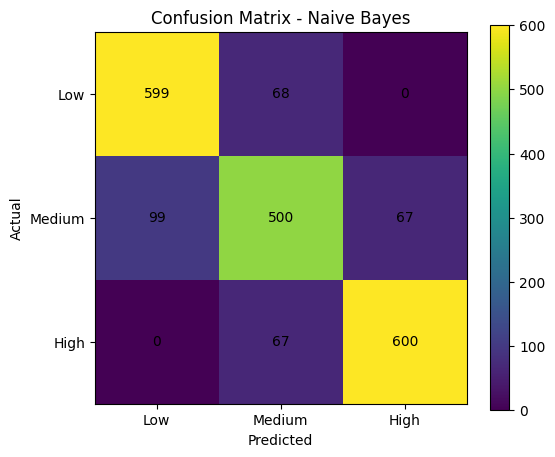

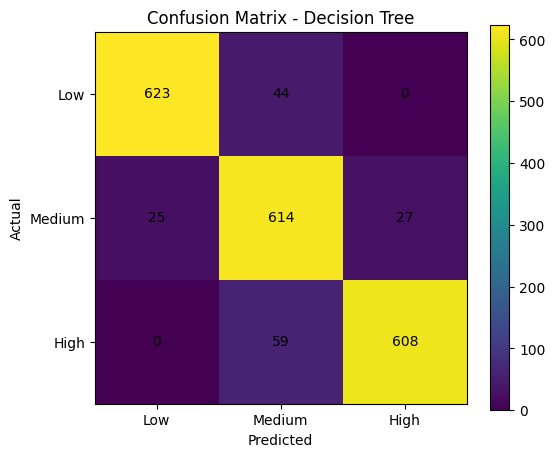

In [23]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    plt.imshow(cm)
    plt.title(title)
    plt.xticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    plt.yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.colorbar()
    plt.show()

plot_confusion_matrix(y_test, y_pred_nb, "Confusion Matrix - Naive Bayes")
plot_confusion_matrix(y_test, y_pred_dt, "Confusion Matrix - Decision Tree")

## 21. Classification Report

In [24]:
print("Classification Report - Naive Bayes")
print(classification_report(y_test, y_pred_nb, target_names=CLASS_ORDER))

print("\nClassification Report - Decision Tree")
print(classification_report(y_test, y_pred_dt, target_names=CLASS_ORDER))

Classification Report - Naive Bayes
              precision    recall  f1-score   support

         Low       0.86      0.90      0.88       667
      Medium       0.79      0.75      0.77       666
        High       0.90      0.90      0.90       667

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000


Classification Report - Decision Tree
              precision    recall  f1-score   support

         Low       0.96      0.93      0.95       667
      Medium       0.86      0.92      0.89       666
        High       0.96      0.91      0.93       667

    accuracy                           0.92      2000
   macro avg       0.93      0.92      0.92      2000
weighted avg       0.93      0.92      0.92      2000



## 22. ROC Curve

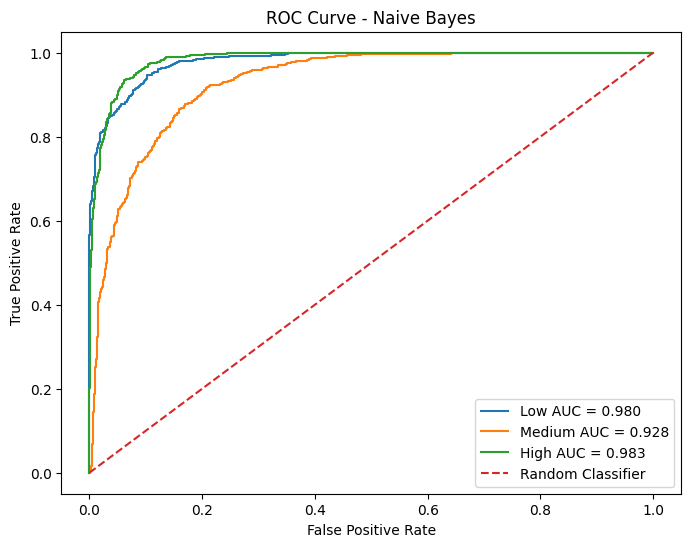

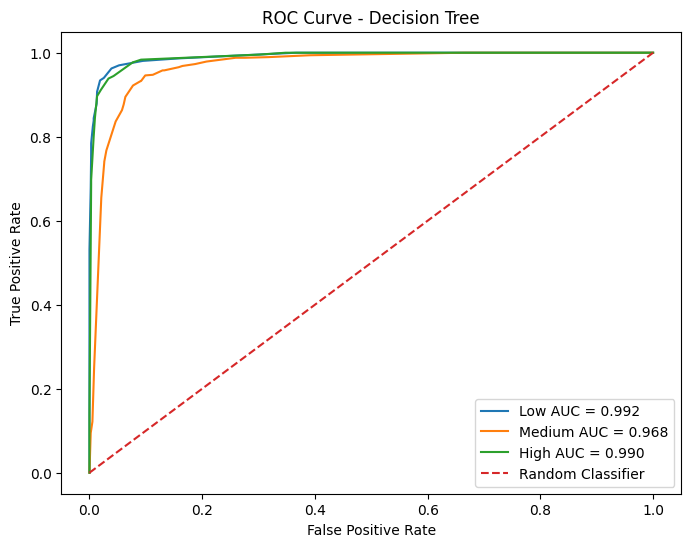

In [25]:
def plot_multiclass_roc(y_true, y_proba, model_name):
    classes = np.arange(len(CLASS_ORDER))
    y_true_bin = label_binarize(y_true, classes=classes)

    plt.figure(figsize=(8, 6))
    for i, class_name in enumerate(CLASS_ORDER):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_name} AUC = {roc_auc:.3f}")

    plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
    plt.title(f"ROC Curve - {model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

plot_multiclass_roc(y_test, y_proba_nb, "Naive Bayes")
plot_multiclass_roc(y_test, y_proba_dt, "Decision Tree")

## 23. Feature Importance

,feature,importance
5,Fertilizer_Used_kg,0.8523
3,Rainfall_mm,0.1476
4,Humidity_pct,0.0001
0,Region,0.0000
1,Soil_Type,0.0000
2,Soil_pH,0.0000
6,Pesticides_Used_kg,0.0000
7,Rainfall_per_Temperature,0.0000
8,Fertilizer_per_Density,0.0000
9,Input_Intensity,0.0000


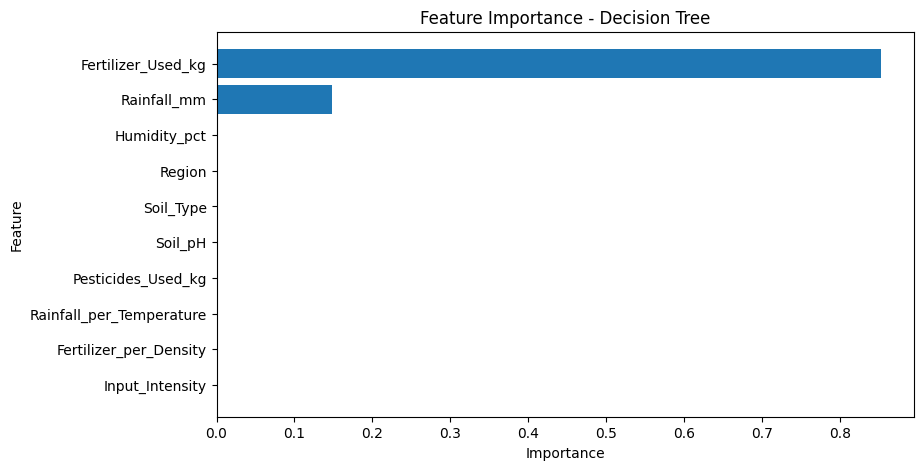

Catatan: Gaussian Naive Bayes tidak memiliki feature_importances_ bawaan.


In [26]:
importance_df = pd.DataFrame({
    "feature": selected_features,
    "importance": dt_model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1])
plt.title("Feature Importance - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

print("Catatan: Gaussian Naive Bayes tidak memiliki feature_importances_ bawaan.")

## 24. Decision Tree Visualization

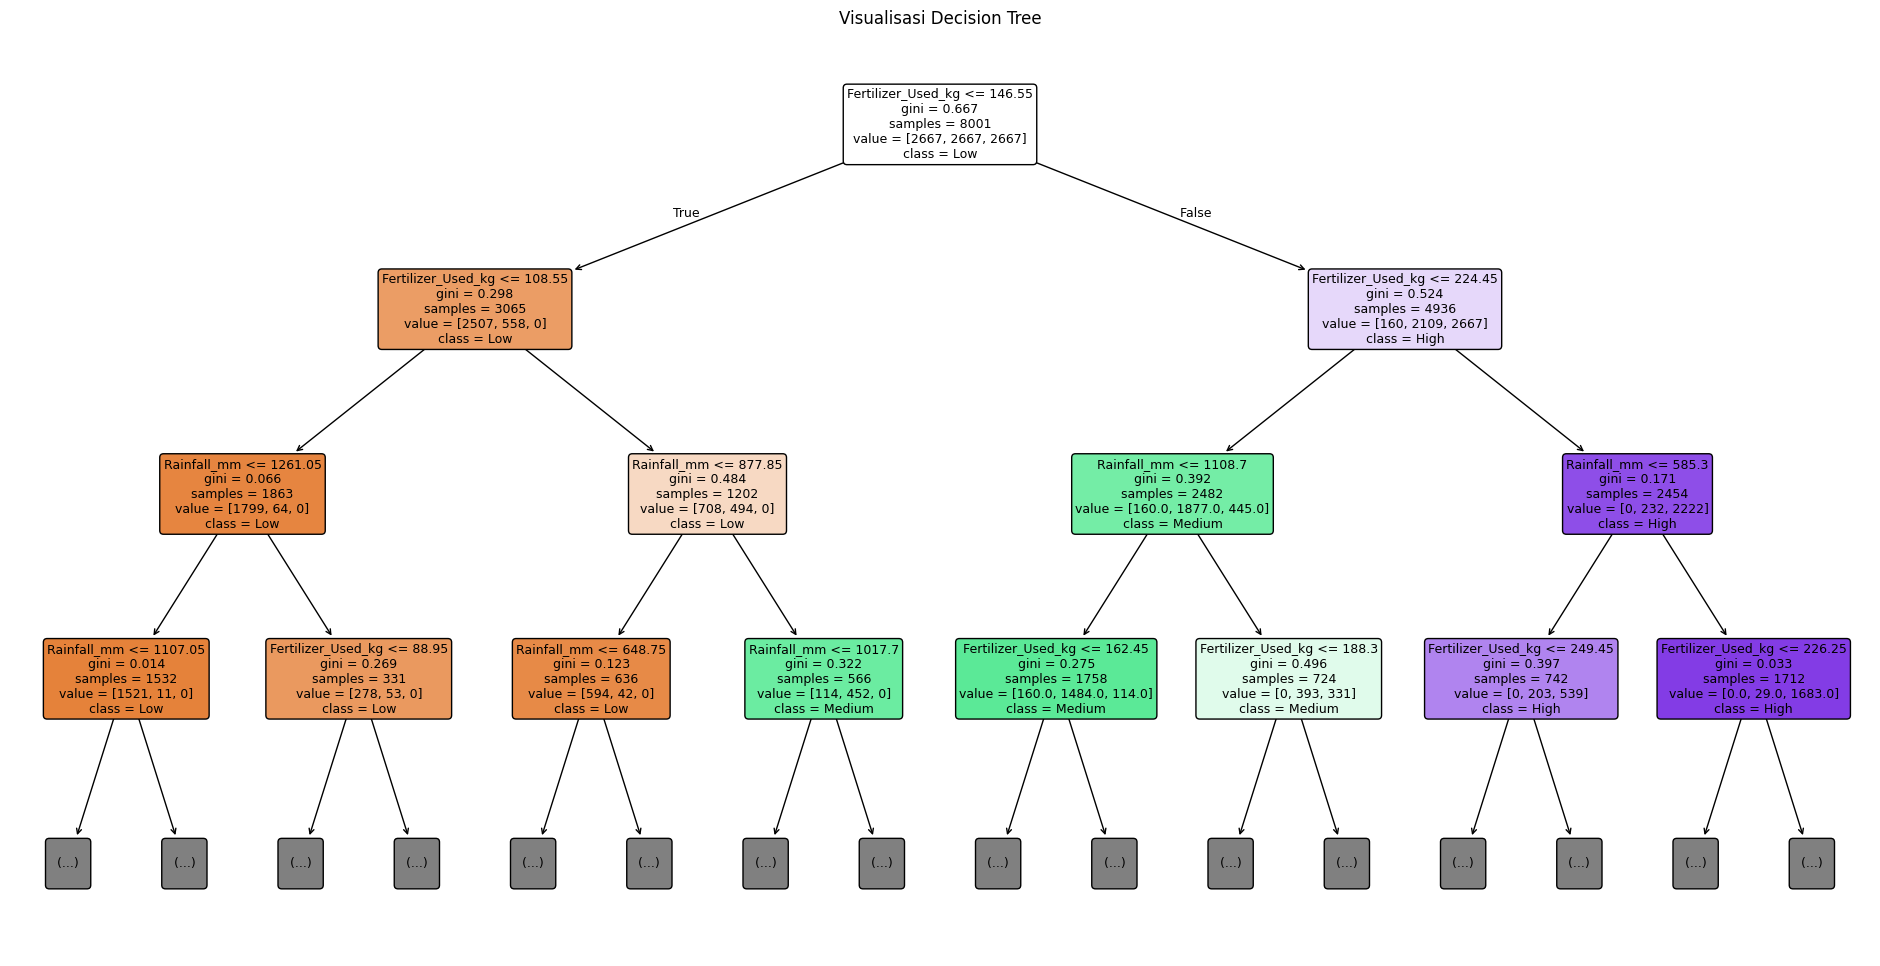

In [27]:
plt.figure(figsize=(24, 12))
plot_tree(
    dt_model,
    feature_names=selected_features,
    class_names=CLASS_ORDER,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)
plt.title("Visualisasi Decision Tree")
plt.show()

## 25. Prediksi Data Baru

In [28]:
new_data = X_test.iloc[[0]].copy()
new_data_selected = mi_selector.transform(new_data)

prediction_encoded = dt_model.predict(new_data_selected)[0]
prediction_label = INT_TO_CLASS[prediction_encoded]
prediction_probability = dt_model.predict_proba(new_data_selected)[0]

print("Contoh data baru:")
display(new_data)

print("\nPrediksi kelas yield:", prediction_label)
print("\nProbabilitas tiap kelas:")
display(pd.DataFrame({
    "class": CLASS_ORDER,
    "probability": prediction_probability
}))

Contoh data baru:


,Crop,Region,Soil_Type,Soil_pH,Rainfall_mm,Temperature_C,Humidity_pct,Fertilizer_Used_kg,Irrigation,Pesticides_Used_kg,Planting_Density,Previous_Crop,Rainfall_per_Temperature,Fertilizer_per_Density,Humidity_Temperature_Index,Input_Intensity
5044,3,2,0,7.0500,877.3000,16.9000,64.0000,74.0000,0,32.0000,5.4000,4,49.0112,11.5625,"1,081.6000",106.0000



Prediksi kelas yield: Low

Probabilitas tiap kelas:


,class,probability
0,Low,1.0000
1,Medium,0.0000
2,High,0.0000


## 26. Save Model

In [29]:
model_package = {
    "naive_bayes_model": nb_model,
    "decision_tree_model": dt_model,
    "feature_selector": mi_selector,
    "selected_features": selected_features,
    "feature_columns": X.columns.tolist(),
    "label_encoders": label_encoders,
    "class_order": CLASS_ORDER,
    "class_to_int": CLASS_TO_INT,
    "int_to_class": INT_TO_CLASS,
    "yield_bins": yield_bins,
    "target_numeric": TARGET_NUMERIC,
    "target_class": TARGET_CLASS,
    "notes": "Target numerik Yield_ton_per_ha dikonversi menjadi kelas Low, Medium, High menggunakan qcut."
}

joblib.dump(model_package, MODEL_OUTPUT_PATH)
print(f"Model berhasil disimpan sebagai: {MODEL_OUTPUT_PATH}")

# Di Google Colab, gunakan kode berikut untuk mengunduh model:
# from google.colab import files
# files.download(MODEL_OUTPUT_PATH)

Model berhasil disimpan sebagai: crop_yield_classification_model_revised.pkl


## 27. Perbandingan Model

In [30]:
comparison_df = evaluation_results.merge(
    cv_results_df,
    left_on="Model",
    right_on="model",
    how="left"
).drop(columns=["model"])

display(comparison_df)

best_model_name = evaluation_results.iloc[0]["Model"]
print(f"Model terbaik berdasarkan F1_weighted pada data test: {best_model_name}")

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OVR_weighted,accuracy_mean,accuracy_std,precision_mean,recall_mean,f1_mean,f1_std
0,Decision Tree,0.9225,0.9251,0.9225,0.9232,0.9833,0.9184,0.0069,0.9197,0.9184,0.9187,0.0066
1,Naive Bayes,0.8495,0.8484,0.8495,0.8487,0.9640,0.8421,0.0076,0.8416,0.8421,0.8417,0.0080


Model terbaik berdasarkan F1_weighted pada data test: Decision Tree


## 28. Ringkasan Hasil

In [31]:
summary = evaluation_results.copy()
cols_to_round = ["Accuracy", "Precision_weighted", "Recall_weighted", "F1_weighted", "ROC_AUC_OVR_weighted"]
summary[cols_to_round] = summary[cols_to_round].round(4)

display(summary)

best_row = summary.iloc[0]
print("Ringkasan:")
print(f"- Model terbaik: {best_row['Model']}")
print(f"- Accuracy     : {best_row['Accuracy']}")
print(f"- Precision    : {best_row['Precision_weighted']}")
print(f"- Recall       : {best_row['Recall_weighted']}")
print(f"- F1-score     : {best_row['F1_weighted']}")
print(f"- ROC AUC OVR  : {best_row['ROC_AUC_OVR_weighted']}")
print("- Fitur final  :", selected_features)

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OVR_weighted
1,Decision Tree,0.9225,0.9251,0.9225,0.9232,0.9833
0,Naive Bayes,0.8495,0.8484,0.8495,0.8487,0.9640


Ringkasan:
- Model terbaik: Decision Tree
- Accuracy     : 0.9225
- Precision    : 0.9251
- Recall       : 0.9225
- F1-score     : 0.9232
- ROC AUC OVR  : 0.9833
- Fitur final  : ['Region', 'Soil_Type', 'Soil_pH', 'Rainfall_mm', 'Humidity_pct', 'Fertilizer_Used_kg', 'Pesticides_Used_kg', 'Rainfall_per_Temperature', 'Fertilizer_per_Density', 'Input_Intensity']


## 29. Kesimpulan

Berdasarkan alur kerja notebook ini, dataset **Smart Crop Yield Prediction** dapat digunakan untuk membangun model klasifikasi tingkat hasil panen. Target asli `Yield_ton_per_ha` yang berbentuk numerik dikonversi menjadi tiga kelas produktivitas: **Low**, **Medium**, dan **High**.

Dua model utama yang digunakan adalah **Gaussian Naive Bayes** dan **Decision Tree Classifier**. Model dievaluasi menggunakan train-test split, cross validation, confusion matrix, classification report, ROC curve, feature importance, dan visualisasi Decision Tree. Berdasarkan hasil pengujian, **Decision Tree** menjadi model terbaik karena mampu menangkap pola ambang dan interaksi fitur lebih baik daripada Naive Bayes.

Seleksi fitur menggunakan empat metode, yaitu **Mutual Information**, **Chi-Square**, **ANOVA F-test**, dan **Decision Tree Importance**. Mutual Information digunakan sebagai selector utama untuk menghasilkan dataset final. Fitur yang paling konsisten memberi sinyal penting adalah fitur terkait pupuk, intensitas input, dan curah hujan.

**Keterbatasan:** kelas Low, Medium, dan High dibentuk berdasarkan kuantil dataset, bukan standar agronomis eksternal. Untuk penelitian lanjutan, threshold kelas dapat dibuat berdasarkan standar produktivitas riil, serta model lain seperti Random Forest Classifier, Gradient Boosting, SVM, atau model regresi dapat diuji sebagai pembanding.

### References

[1] A. Chlingaryan, S. Sukkarieh, and B. Whelan, “Machine learning approaches for crop yield prediction and nitrogen status estimation in precision agriculture: A review,” *Computers and Electronics in Agriculture*, 151, 61–69 (2018).

[2] T. van Klompenburg, A. Kassahun, and C. Catal, “Crop yield prediction using machine learning: A systematic literature review,” *Computers and Electronics in Agriculture*, 177, 105709 (2020).

[3] M. I. Miadul, “Smart Crop yield predication dataset,” Kaggle Dataset (2025).

[4] N. V. Chawla, K. W. Bowyer, L. O. Hall, and W. P. Kegelmeyer, “SMOTE: Synthetic Minority Over-sampling Technique,” *Journal of Artificial Intelligence Research*, 16, 321–357 (2002).

[5] I. Rish, “An empirical study of the naive Bayes classifier,” in *IJCAI 2001 Workshop on Empirical Methods in Artificial Intelligence* (2001), pp. 41–46.

[6] J. R. Quinlan, “Induction of decision trees,” *Machine Learning*, 1, 81–106 (1986).